# Vehicle Registration Prediction Using Machine Learning Models

by MD. ZIHADUL AHSAN RATUL

---


## Project Information

**Project Title:** Vehicle Registration Prediction System

**Problem Type:** Supervised Machine Learning Regression

**Objective:** Predict vehicle registration numbers using different regression-based machine learning models.

**Development Platform:** Google Colab (Python)




##**XGBOOST**

#Import Required Libraries

In [ ]:
# Data manipulation libraries

import pandas as pd
import numpy as np


# Visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns


# Machine learning libraries

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler
)


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# XGBoost

from xgboost import (
    XGBClassifier,
    plot_importance
)


# Model saving

import pickle


# Warning control

import warnings
warnings.filterwarnings("ignore")


print("All required libraries imported successfully.")

All required libraries imported successfully.


#Load Dataset

In [ ]:
df = pd.read_csv(
    "cleaned_registrations.csv"
)


print(
    "Dataset Loaded Successfully"
)


display(
    df.head()
)

Dataset Loaded Successfully


,type,fuel,registrations,year,month,day
0,0,0,51261,2000,1,1
1,0,0,46478,2000,2,1
2,0,0,57477,2000,3,1
3,0,0,50941,2000,4,1
4,0,0,53361,2000,5,1


#Dataset Overview

In [ ]:
print(
    "Total Rows:",
    df.shape[0]
)


print(
    "Total Columns:",
    df.shape[1]
)


print(
    "\nColumn Names:"
)


for column in df.columns:

    print(
        "-",
        column
    )

Total Rows: 10727
Total Columns: 6

Column Names:
- type
- fuel
- registrations
- year
- month
- day


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10727 entries, 0 to 10726
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   type           10727 non-null  int64
 1   fuel           10727 non-null  int64
 2   registrations  10727 non-null  int64
 3   year           10727 non-null  int64
 4   month          10727 non-null  int64
 5   day            10727 non-null  int64
dtypes: int64(6)
memory usage: 503.0 KB


In [ ]:
display(
    df.describe(
        include="all"
    )
)

,type,fuel,registrations,year,month,day
count,10727.000000,10727.000000,10727.000000,10727.000000,10727.000000,10727.0
mean,2.908549,2.812622,11365.969609,2013.038408,6.454554,1.0
std,2.037484,2.201557,25816.093850,7.564972,3.463100,0.0
min,0.000000,0.000000,1.000000,2000.000000,1.000000,1.0
25%,1.000000,1.000000,68.000000,2007.000000,3.000000,1.0
50%,3.000000,3.000000,385.000000,2013.000000,6.000000,1.0
75%,5.000000,5.000000,2398.500000,2020.000000,9.000000,1.0
max,6.000000,6.000000,162090.000000,2026.000000,12.000000,1.0


#Data Quality Checking

In [ ]:
missing_values = pd.DataFrame(
    {
        "Missing Values":
        df.isnull().sum(),

        "Percentage":
        df.isnull().sum()
        /
        len(df)
        *
        100
    }
)


display(
    missing_values
)

,Missing Values,Percentage
type,0,0.0
fuel,0,0.0
registrations,0,0.0
year,0,0.0
month,0,0.0
day,0,0.0


In [ ]:
duplicate_count = (
    df
    .duplicated()
    .sum()
)


print(
    "Duplicate Records:",
    duplicate_count
)

Duplicate Records: 0


#Exploratory Data Analysis

<Figure size 1200x600 with 0 Axes>

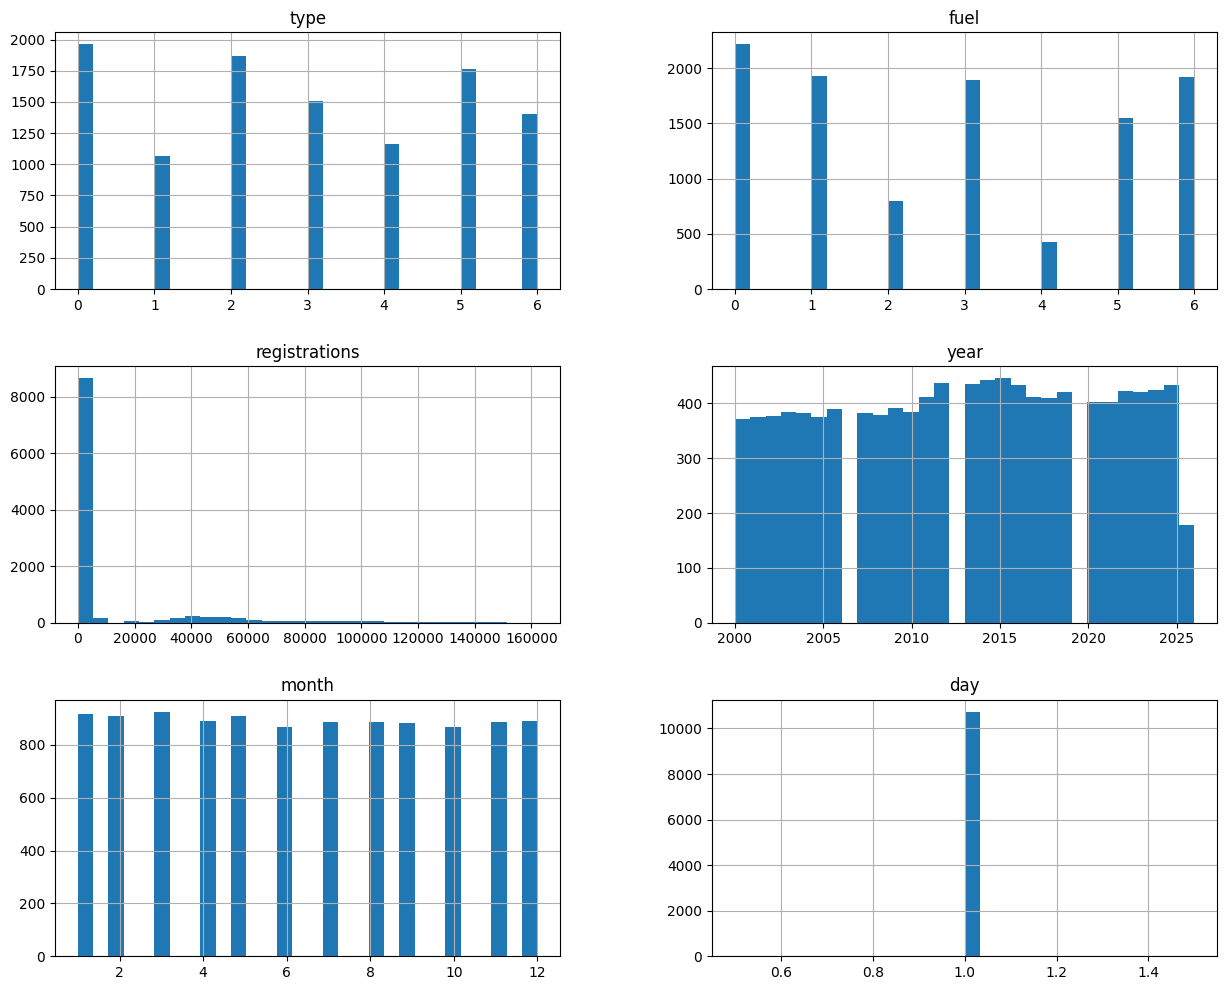

In [ ]:
plt.figure(
    figsize=(12,6)
)


df.hist(
    figsize=(15,12),
    bins=30
)


plt.show()

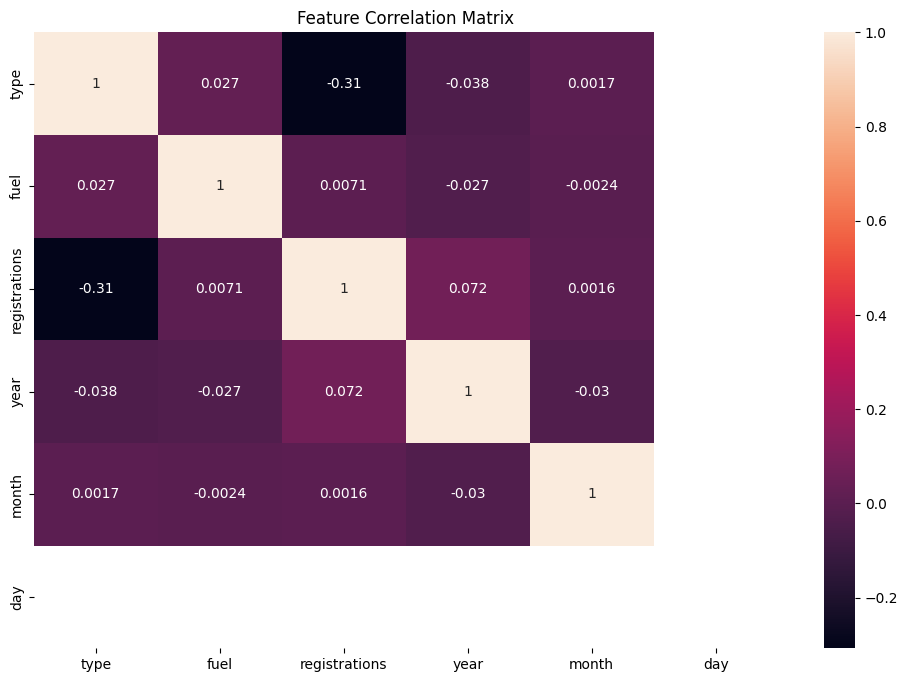

In [ ]:
numeric_columns = (
    df
    .select_dtypes(
        include=np.number
    )
)


plt.figure(
    figsize=(12,8)
)


sns.heatmap(
    numeric_columns.corr(),
    annot=True
)


plt.title(
    "Feature Correlation Matrix"
)


plt.show()

#Data Preprocessing

In [ ]:
processed_df = (
    df.copy()
)


processed_df.head()

,type,fuel,registrations,year,month,day
0,0,0,51261,2000,1,1
1,0,0,46478,2000,2,1
2,0,0,57477,2000,3,1
3,0,0,50941,2000,4,1
4,0,0,53361,2000,5,1


In [ ]:
encoder_dictionary = {}


for column in processed_df.columns:


    if processed_df[column].dtype == "object":


        encoder = LabelEncoder()


        processed_df[column] = (
            encoder.fit_transform(
                processed_df[column]
            )
        )


        encoder_dictionary[column] = encoder



display(
    processed_df.head()
)

,type,fuel,registrations,year,month,day
0,0,0,51261,2000,1,1
1,0,0,46478,2000,2,1
2,0,0,57477,2000,3,1
3,0,0,50941,2000,4,1
4,0,0,53361,2000,5,1


#Feature and Target Selection

In [ ]:
# Define target variable for prediction


target = "registrations"



# Separate independent features and dependent variable


X = processed_df.drop(

    target,

    axis=1

)
y = processed_df[target]
print(

    "Input Features:"
)
print(

    X.columns

)
print(

    "\nTarget Variable:"

)
print(

    target

)
print(

    "\nFeature Shape:",

    X.shape

)

print(

    "Target Shape:",

    y.shape

)

Input Features:
Index(['type', 'fuel', 'year', 'month', 'day'], dtype='object')

Target Variable:
registrations

Feature Shape: (10727, 5)
Target Shape: (10727,)


#Training and Testing Data Split

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(


    X,


    y,


    test_size=0.30,


    random_state=42

)
print(

    "Training Dataset Size:",

    X_train.shape
)
print(

    "Testing Dataset Size:",

    X_test.shape
)

Training Dataset Size: (7508, 5)
Testing Dataset Size: (3219, 5)


#Baseline XGBoost Regression Model

In [ ]:
from xgboost import XGBRegressor
baseline_xgb = XGBRegressor(

    objective="reg:squarederror",

    random_state=42
)
baseline_xgb.fit(
    X_train,
    y_train

)

print(

    "Baseline XGBoost Regression Model Training Completed"

)

Baseline XGBoost Regression Model Training Completed


In [ ]:
baseline_prediction = baseline_xgb.predict(


    X_test

)



print(

    "Prediction Completed"

)

Prediction Completed


#Baseline Model Evaluation

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np



baseline_mae = mean_absolute_error(

    y_test,

    baseline_prediction

)



baseline_rmse = np.sqrt(

    mean_squared_error(

        y_test,

        baseline_prediction

    )

)



baseline_r2 = r2_score(

    y_test,

    baseline_prediction

)



print(

    "Baseline MAE:",

    baseline_mae

)



print(

    "Baseline RMSE:",

    baseline_rmse

)



print(

    "Baseline R2 Score:",

    baseline_r2

)

Baseline MAE: 1514.1866455078125
Baseline RMSE: 3855.5349823338397
Baseline R2 Score: 0.9773448705673218


#Hyperparameter Optimization using GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV



parameter_grid = {


    "n_estimators":

    [

        100,

        200,

        300

    ],



    "max_depth":

    [

        3,

        5,

        7

    ],



    "learning_rate":

    [

        0.01,

        0.05,

        0.1

    ],



    "subsample":

    [

        0.8,

        1.0

    ]

}



print(

    "Parameter Grid Created"

)

Parameter Grid Created


In [ ]:
grid_search = GridSearchCV(


    estimator=XGBRegressor(

        objective="reg:squarederror",

        random_state=42

    ),



    param_grid=parameter_grid,



    cv=5,



    scoring="r2",



    n_jobs=-1,



    verbose=1


)



grid_search.fit(


    X_train,


    y_train

)



print(

    "Hyperparameter Optimization Completed"

)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Hyperparameter Optimization Completed


In [ ]:
print(

    "Best Parameters:"

)



print(

    grid_search.best_params_

)



print(

    "\nBest Cross Validation Score:"

)



print(

    grid_search.best_score_

)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}

Best Cross Validation Score:
0.9762322306632996


#Optimized XGBoost Model Training

In [ ]:
optimized_xgb = grid_search.best_estimator_



optimized_xgb.fit(


    X_train,


    y_train

)



print(

    "Optimized XGBoost Model Training Completed"

)

Optimized XGBoost Model Training Completed


#Final XGBoost Prediction

In [ ]:
final_prediction = optimized_xgb.predict(


    X_test

)



prediction_result = pd.DataFrame(

    {


        "Actual Registrations":

        y_test.values,



        "Predicted Registrations":

        final_prediction.astype(int)

    }

)



display(

    prediction_result.head(20)

)

,Actual Registrations,Predicted Registrations
0,2285,2045
1,2339,2461
2,2183,2355
3,138,179
4,1185,1368
5,800,1166
6,50,210
7,4,-56
8,382,387
9,1,-1299


#Optimized Model Performance Evaluation

In [ ]:
optimized_mae = mean_absolute_error(


    y_test,


    final_prediction

)



optimized_rmse = np.sqrt(


    mean_squared_error(

        y_test,


        final_prediction

    )

)



optimized_r2 = r2_score(


    y_test,


    final_prediction

)



evaluation_table = pd.DataFrame(

    {


        "Evaluation Metric":

        [

            "Mean Absolute Error (MAE)",

            "Root Mean Squared Error (RMSE)",

            "R2 Score"

        ],



        "Result":

        [

            optimized_mae,


            optimized_rmse,


            optimized_r2

        ]

    }

)



display(

    evaluation_table

)

,Evaluation Metric,Result
0,Mean Absolute Error (MAE),1364.471069
1,Root Mean Squared Error (RMSE),3948.752968
2,R2 Score,0.976236


#Baseline and Optimized Model Comparison

In [ ]:
comparison_table = pd.DataFrame(

    {


        "Model":

        [

            "Baseline XGBoost",

            "Optimized XGBoost"

        ],



        "MAE":

        [

            baseline_mae,

            optimized_mae

        ],



        "RMSE":

        [

            baseline_rmse,

            optimized_rmse

        ],



        "R2 Score":

        [

            baseline_r2,

            optimized_r2

        ]

    }

)



display(

    comparison_table

)

,Model,MAE,RMSE,R2 Score
0,Baseline XGBoost,1514.186646,3855.534982,0.977345
1,Optimized XGBoost,1364.471069,3948.752968,0.976236


#Actual vs Predicted Registration Analysis

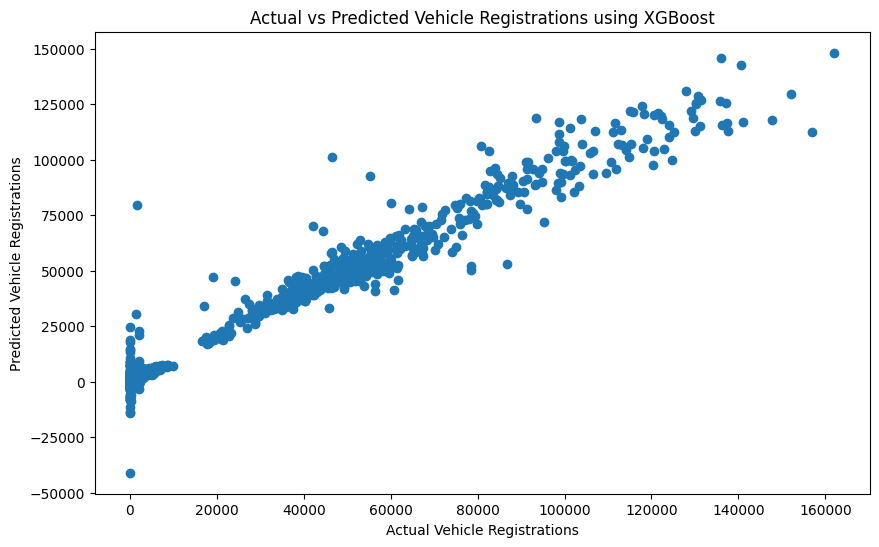

In [ ]:
plt.figure(

    figsize=(10,6)

)



plt.scatter(

    y_test,


    final_prediction

)



plt.xlabel(

    "Actual Vehicle Registrations"

)



plt.ylabel(

    "Predicted Vehicle Registrations"

)



plt.title(

    "Actual vs Predicted Vehicle Registrations using XGBoost"

)



plt.show()

#Prediction Error Analysis

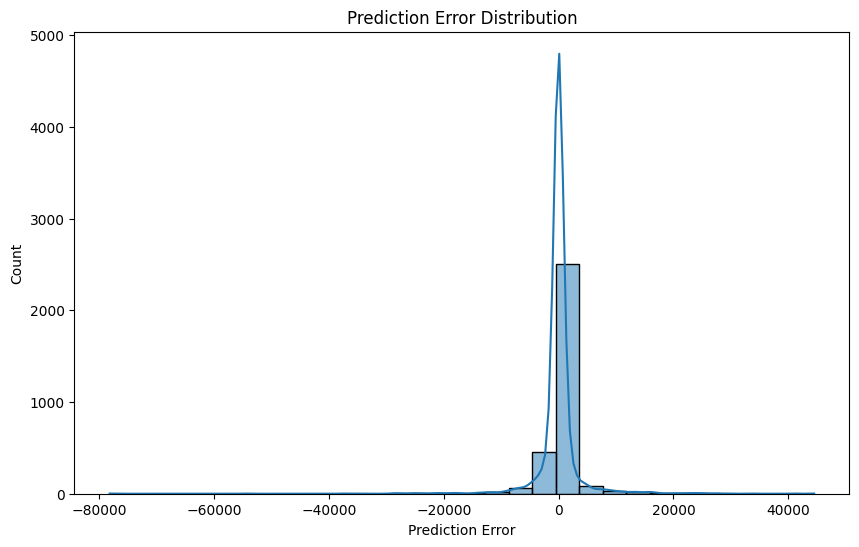

In [ ]:
errors = (

    y_test -

    final_prediction

)



plt.figure(

    figsize=(10,6)

)



sns.histplot(

    errors,

    bins=30,

    kde=True

)



plt.title(

    "Prediction Error Distribution"

)



plt.xlabel(

    "Prediction Error"

)



plt.show()

#XGBoost Feature Importance Analysis

In [ ]:
feature_importance = pd.DataFrame(

    {


        "Feature":

        X.columns,



        "Importance":

        optimized_xgb.feature_importances_

    }

)



feature_importance = feature_importance.sort_values(


    by="Importance",


    ascending=False

)



display(

    feature_importance

)

,Feature,Importance
1,fuel,0.662652
0,type,0.297086
2,year,0.029188
3,month,0.011075
4,day,0.000000


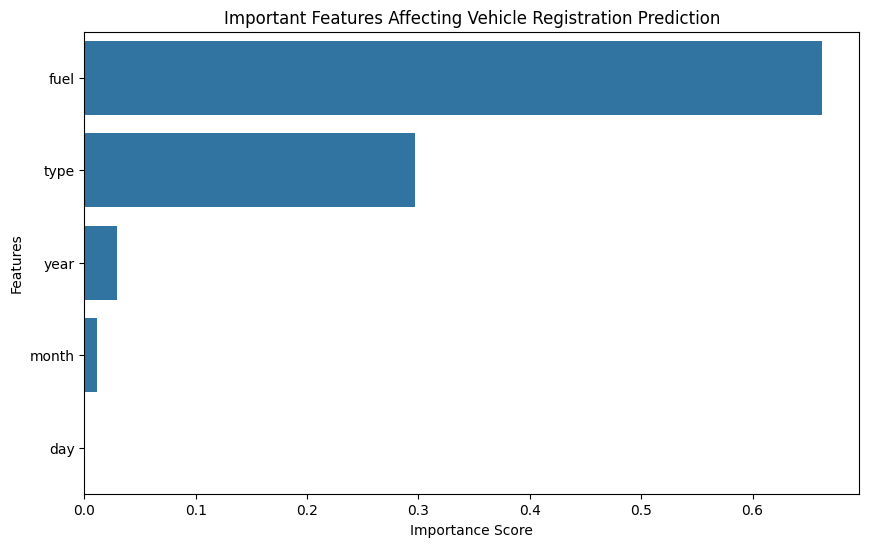

In [ ]:
plt.figure(

    figsize=(10,6)

)



sns.barplot(


    data=feature_importance,


    x="Importance",


    y="Feature"

)



plt.title(

    "Important Features Affecting Vehicle Registration Prediction"

)



plt.xlabel(

    "Importance Score"

)



plt.ylabel(

    "Features"

)



plt.show()

#**K-Fold Cross Validation**

In [ ]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score


kfold = KFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)



cross_validation_scores = cross_val_score(


    optimized_xgb,


    X,


    y,


    cv=kfold,


    scoring="r2"

)



print(

    "Cross Validation R2 Scores:"

)



print(

    cross_validation_scores

)



print(

    "\nAverage Cross Validation R2 Score:"

)



print(

    cross_validation_scores.mean()

)

Cross Validation R2 Scores:
[0.97635853 0.97729659 0.97708142 0.97898096 0.98179436]

Average Cross Validation R2 Score:
0.9783023715019226


#Save Final Machine Learning Model

In [ ]:
import pickle



with open(

    "XGBoost_Vehicle_Registration_Model.pkl",

    "wb"

) as file:


    pickle.dump(

        optimized_xgb,

        file

    )



print(

    "XGBoost Model Saved Successfully"

)

XGBoost Model Saved Successfully


#Final Model Summary

In [ ]:
print(

f"""

FINAL MACHINE LEARNING MODEL SUMMARY


Project:
Vehicle Registration Prediction


Algorithm:
Extreme Gradient Boosting Regression (XGBoost)


Machine Learning Type:
Supervised Regression


Input Features:

• Month
• Year
• Day
• Vehicle Type
• Fuel Type


Target Variable:

Number of Vehicle Registrations


Optimization Method:

GridSearchCV Hyperparameter Tuning


Validation:

5-Fold Cross Validation


Evaluation Metrics:

Mean Absolute Error (MAE):
{optimized_mae:.2f}


Root Mean Squared Error (RMSE):
{optimized_rmse:.2f}


R2 Score:
{optimized_r2:.4f}


Model Accuracy Interpretation:

The model explains approximately {optimized_r2 * 100:.2f}%
of the variation in vehicle registration data.


Conclusion:

The optimized XGBoost regression model successfully predicts vehicle registration numbers by learning historical vehicle registration patterns.

"""

)



FINAL MACHINE LEARNING MODEL SUMMARY


Project:
Vehicle Registration Prediction


Algorithm:
Extreme Gradient Boosting Regression (XGBoost)


Machine Learning Type:
Supervised Regression


Input Features:

• Month
• Year
• Day
• Vehicle Type
• Fuel Type


Target Variable:

Number of Vehicle Registrations


Optimization Method:

GridSearchCV Hyperparameter Tuning


Validation:

5-Fold Cross Validation


Evaluation Metrics:

Mean Absolute Error (MAE):
1364.47


Root Mean Squared Error (RMSE):
3948.75


R2 Score:
0.9762


Model Accuracy Interpretation:

The model explains approximately 97.62%
of the variation in vehicle registration data.


Conclusion:

The optimized XGBoost regression model successfully predicts vehicle registration numbers by learning historical vehicle registration patterns.




##**RANDOM FOREST MODEL**

1. Import Data

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

2. Load Dataset

In [ ]:
df = pd.read_csv("/content/cleaned_registrations.csv")

3. Dataset Overview

In [ ]:
df.head()

,type,fuel,registrations,year,month,day
0,0,0,51261,2000,1,1
1,0,0,46478,2000,2,1
2,0,0,57477,2000,3,1
3,0,0,50941,2000,4,1
4,0,0,53361,2000,5,1


In [ ]:
df.shape

(10727, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10727 entries, 0 to 10726
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   type           10727 non-null  int64
 1   fuel           10727 non-null  int64
 2   registrations  10727 non-null  int64
 3   year           10727 non-null  int64
 4   month          10727 non-null  int64
 5   day            10727 non-null  int64
dtypes: int64(6)
memory usage: 503.0 KB


In [ ]:
df.describe(include='all')

,type,fuel,registrations,year,month,day
count,10727.000000,10727.000000,10727.000000,10727.000000,10727.000000,10727.0
mean,2.908549,2.812622,11365.969609,2013.038408,6.454554,1.0
std,2.037484,2.201557,25816.093850,7.564972,3.463100,0.0
min,0.000000,0.000000,1.000000,2000.000000,1.000000,1.0
25%,1.000000,1.000000,68.000000,2007.000000,3.000000,1.0
50%,3.000000,3.000000,385.000000,2013.000000,6.000000,1.0
75%,5.000000,5.000000,2398.500000,2020.000000,9.000000,1.0
max,6.000000,6.000000,162090.000000,2026.000000,12.000000,1.0


4. Verify Dataset

In [ ]:
df.isnull().sum()

,0
type,0
fuel,0
registrations,0
year,0
month,0
day,0


In [ ]:
df.duplicated().sum()

np.int64(0)

5. Target Distribution

In [ ]:
df["fuel"].value_counts()

,count
fuel,
0,2214
1,1931
6,1923
3,1896
5,1548
2,793
4,422


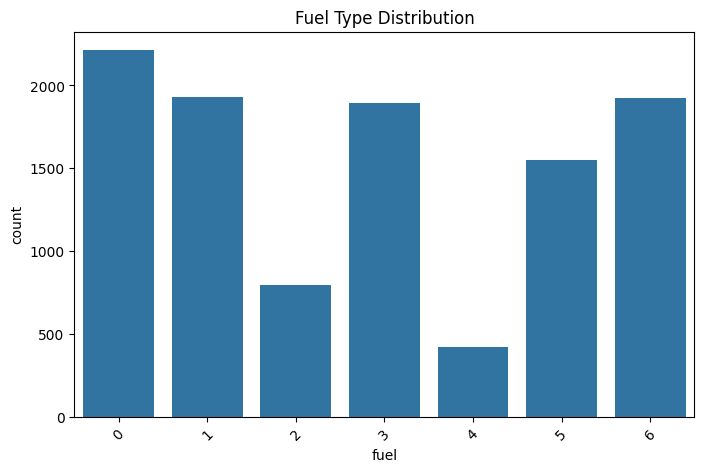

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df,x="fuel")

plt.title("Fuel Type Distribution")

plt.xticks(rotation=45)

plt.show()

6. Encode Categorical Columns

In [ ]:
encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = encoder.fit_transform(df[col])

7. Feature & Target

In [ ]:
X = df.drop("fuel",axis=1)

y = df["fuel"]

8. Train-Test Split

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

9. Build Random Forest

In [ ]:
rf=RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

10. Prediction

In [ ]:
y_pred=rf.predict(X_test)

11. Accuracy

In [ ]:
accuracy=accuracy_score(y_test,y_pred)

print("Accuracy:",accuracy)

Accuracy: 0.6505125815470643


12. Classification Report

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.54      0.53      0.54       423
           1       0.74      0.77      0.75       411
           2       0.72      0.76      0.74       149
           3       0.71      0.69      0.70       374
           4       0.53      0.58      0.56        81
           5       0.73      0.68      0.71       324
           6       0.55      0.57      0.56       384

    accuracy                           0.65      2146
   macro avg       0.65      0.65      0.65      2146
weighted avg       0.65      0.65      0.65      2146



13. Confusion Matrix

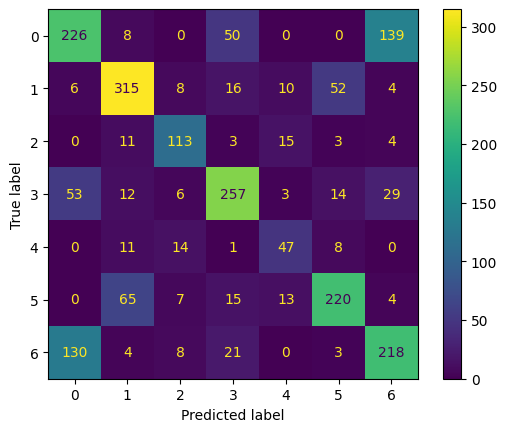

In [ ]:
cm=confusion_matrix(y_test,y_pred)

disp=ConfusionMatrixDisplay(cm)

disp.plot()

plt.show()

14. Feature Importance

In [ ]:
importance=rf.feature_importances_

feature_importance=pd.DataFrame({
    "Feature":X.columns,
    "Importance":importance
})

feature_importance=feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
1,registrations,0.638681
2,year,0.144416
0,type,0.130240
3,month,0.086663
4,day,0.000000


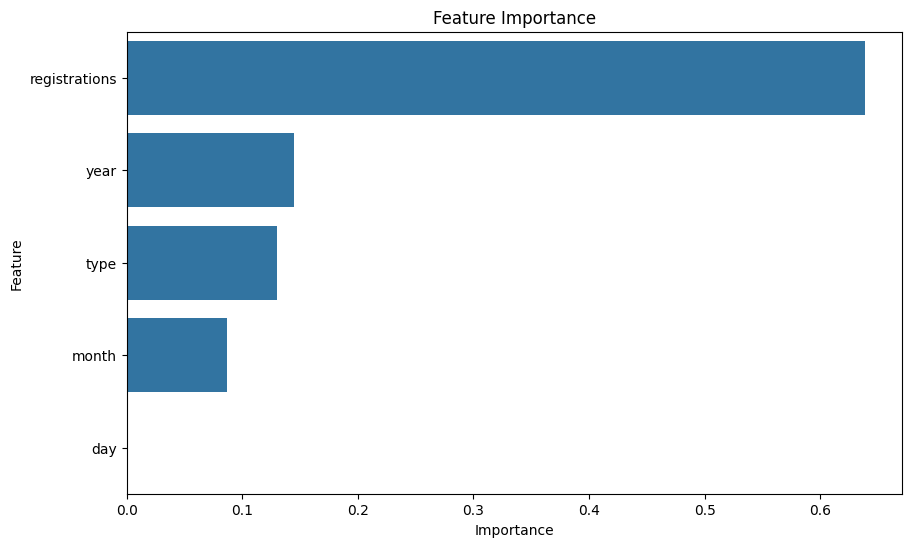

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

# Final Result of Random Forest

In [ ]:
# Random Forest Regressor Model

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluation Metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

# Display Results
print("===== Random Forest Regressor Results =====")
print(f"Mean Absolute Error (MAE): {rf_mae:.4f}")
print(f"Mean Squared Error (MSE): {rf_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rf_rmse:.4f}")
print(f"R² Score: {rf_r2:.4f}")

===== Random Forest Regressor Results =====
Mean Absolute Error (MAE): 1221.7706
Mean Squared Error (MSE): 19175185.6369
Root Mean Squared Error (RMSE): 4378.9480
R² Score: 0.9721


##**DECISION TREE REGRESSOR**

1. Import Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

2. Load Data

In [ ]:
df = pd.read_csv("cleaned_registrations.csv")

In [ ]:
df.head()

,type,fuel,registrations,year,month,day
0,0,0,51261,2000,1,1
1,0,0,46478,2000,2,1
2,0,0,57477,2000,3,1
3,0,0,50941,2000,4,1
4,0,0,53361,2000,5,1


3. Define Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10727 entries, 0 to 10726
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   type           10727 non-null  int64
 1   fuel           10727 non-null  int64
 2   registrations  10727 non-null  int64
 3   year           10727 non-null  int64
 4   month          10727 non-null  int64
 5   day            10727 non-null  int64
dtypes: int64(6)
memory usage: 503.0 KB


In [ ]:
df.describe()

,type,fuel,registrations,year,month,day
count,10727.000000,10727.000000,10727.000000,10727.000000,10727.000000,10727.0
mean,2.908549,2.812622,11365.969609,2013.038408,6.454554,1.0
std,2.037484,2.201557,25816.093850,7.564972,3.463100,0.0
min,0.000000,0.000000,1.000000,2000.000000,1.000000,1.0
25%,1.000000,1.000000,68.000000,2007.000000,3.000000,1.0
50%,3.000000,3.000000,385.000000,2013.000000,6.000000,1.0
75%,5.000000,5.000000,2398.500000,2020.000000,9.000000,1.0
max,6.000000,6.000000,162090.000000,2026.000000,12.000000,1.0


In [ ]:
df.shape

(10727, 6)

In [ ]:
df.isnull().sum()

,0
type,0
fuel,0
registrations,0
year,0
month,0
day,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
type,7
fuel,7
registrations,4302
year,27
month,12
day,1


In [ ]:
df["type"].value_counts()

,count
type,
0,1960
2,1865
5,1761
3,1506
6,1404
4,1164
1,1067


In [ ]:
df["fuel"].value_counts()

,count
fuel,
0,2214
1,1931
6,1923
3,1896
5,1548
2,793
4,422


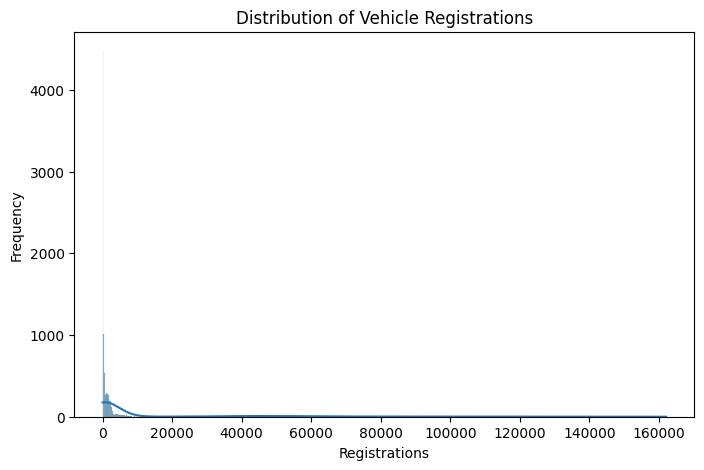

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["registrations"], kde=True)

plt.title("Distribution of Vehicle Registrations")

plt.xlabel("Registrations")

plt.ylabel("Frequency")

plt.show()

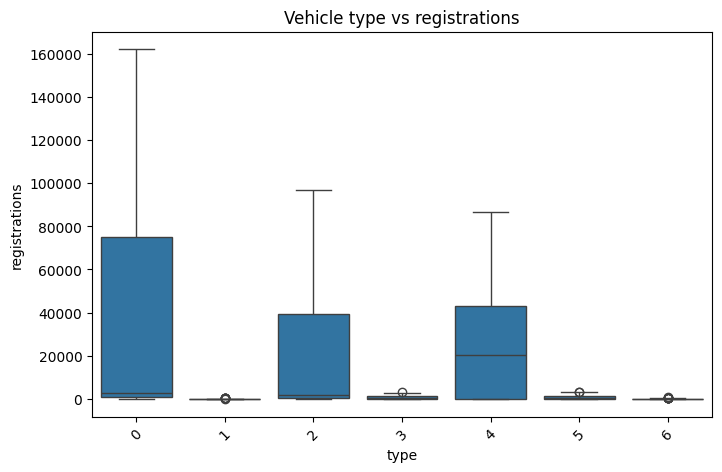

In [ ]:
#Vehicle type vs registrations
plt.figure(figsize=(8,5))

sns.boxplot(
    x="type",
    y="registrations",
    data=df
)
plt.title("Vehicle type vs registrations")

plt.xticks(rotation=45)

plt.show()

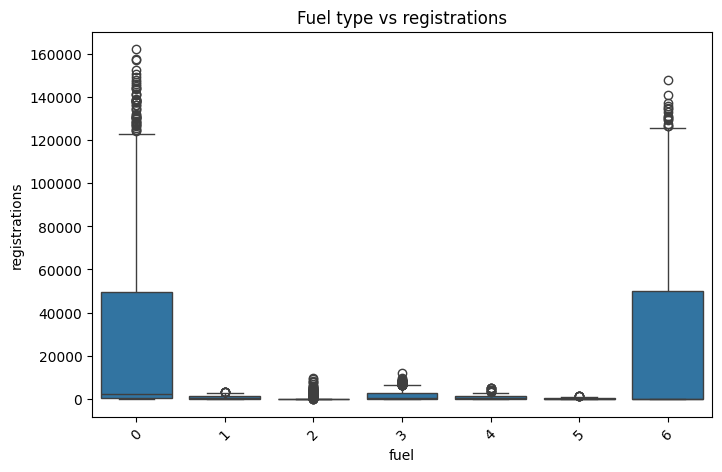

In [ ]:
#Fuel type vs registrations
plt.figure(figsize=(8,5))

sns.boxplot(
    x="fuel",
    y="registrations",
    data=df
)
plt.title("Fuel type vs registrations")

plt.xticks(rotation=45)

plt.show()

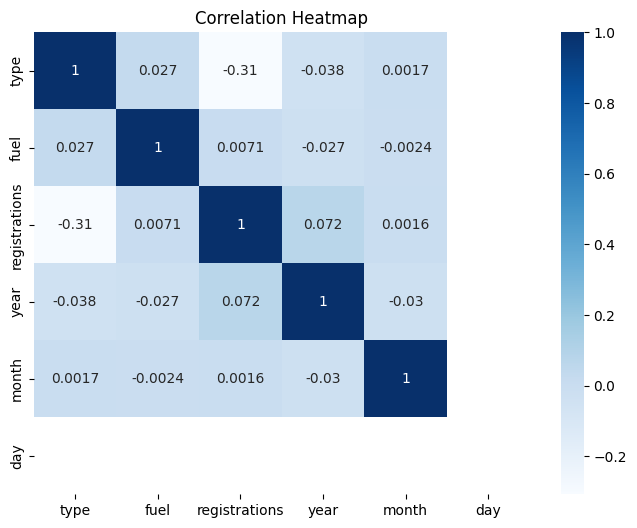

In [ ]:
#Correlation heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Heatmap")

plt.show()

4. DEFINE FEATURES AND TARGET

In [ ]:
X = df.drop("registrations", axis=1)

y = df["registrations"]

In [ ]:
print(X.head())

   type  fuel  year  month  day
0     0     0  2000      1    1
1     0     0  2000      2    1
2     0     0  2000      3    1
3     0     0  2000      4    1
4     0     0  2000      5    1


In [ ]:
print(y.head())

0    51261
1    46478
2    57477
3    50941
4    53361
Name: registrations, dtype: int64


5. TRAIN / TEST SPLIT

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
print("Training Set:", X_train.shape)

print("Testing Set:", X_test.shape)

Training Set: (8581, 5)
Testing Set: (2146, 5)


6. BASELINE MODEL

In [ ]:
# Build Baseline Decision Tree Regressor
baseline_model = DecisionTreeRegressor(random_state=42)

baseline_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
baseline_pred = baseline_model.predict(X_test)

In [ ]:
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print("===== Baseline Model Performance =====")
print(f"MAE      : {baseline_mae:.2f}")
print(f"MSE      : {baseline_mse:.2f}")
print(f"RMSE     : {baseline_rmse:.2f}")
print(f"R² Score : {baseline_r2:.4f}")

===== Baseline Model Performance =====
MAE      : 1444.75
MSE      : 28240525.28
RMSE     : 5314.18
R² Score : 0.9589


7. HYPERPARAMETER OPTIMIZATION

In [ ]:
#Define parameter grid
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [ ]:
#Perform grid search
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

In [ ]:
#Display the Best Parameters
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10}


8. OPTIMIZED MODEL

In [ ]:
optimized_model = grid_search.best_estimator_

In [ ]:
optimized_pred = optimized_model.predict(X_test)

In [ ]:
optimized_mae = mean_absolute_error(y_test, optimized_pred)
optimized_mse = mean_squared_error(y_test, optimized_pred)
optimized_rmse = np.sqrt(optimized_mse)
optimized_r2 = r2_score(y_test, optimized_pred)

print("===== Optimized Model Performance =====")
print(f"MAE      : {optimized_mae:.2f}")
print(f"MSE      : {optimized_mse:.2f}")
print(f"RMSE     : {optimized_rmse:.2f}")
print(f"R² Score : {optimized_r2:.4f}")

===== Optimized Model Performance =====
MAE      : 1413.70
MSE      : 29150608.18
RMSE     : 5399.13
R² Score : 0.9576


9. MODEL COMPARISON

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Optimized"],
    "MAE": [baseline_mae, optimized_mae],
    "MSE": [baseline_mse, optimized_mse],
    "RMSE": [baseline_rmse, optimized_rmse],
    "R² Score": [baseline_r2, optimized_r2]
})

comparison

,Model,MAE,MSE,RMSE,R² Score
0,Baseline,1444.745107,2.824053e+07,5314.181525,0.958899
1,Optimized,1413.700812,2.915061e+07,5399.130317,0.957575


In [ ]:
comparison.round(2)

,Model,MAE,MSE,RMSE,R² Score
0,Baseline,1444.75,28240525.28,5314.18,0.96
1,Optimized,1413.70,29150608.18,5399.13,0.96


10. ACTUAL VS PREDICTED PLOT

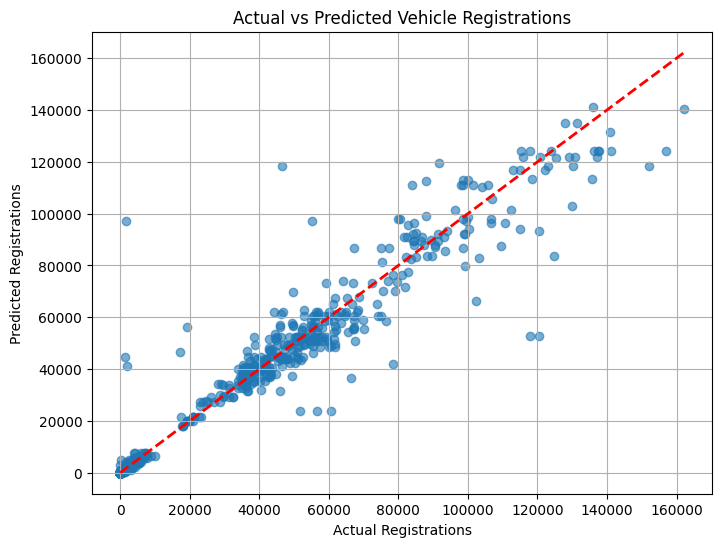

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, optimized_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.title("Actual vs Predicted Vehicle Registrations")

plt.xlabel("Actual Registrations")

plt.ylabel("Predicted Registrations")

plt.grid(True)

plt.show()

11. FEATURE IMPORTANCE

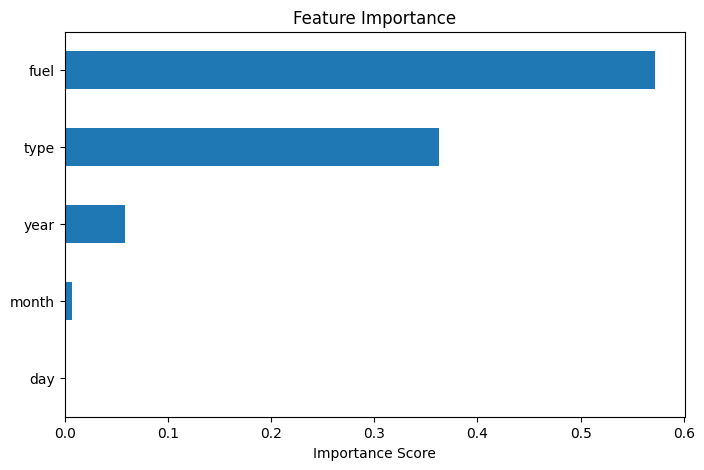

fuel     0.572315
type     0.362358
year     0.058183
month    0.007144
day      0.000000
dtype: float64


In [ ]:
feature_importance = pd.Series(
    optimized_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8,5))

feature_importance.plot(kind="barh")

plt.title("Feature Importance")

plt.xlabel("Importance Score")

plt.show()

print(feature_importance.sort_values(ascending=False))

12. DECISION TREE VISUALIZATION

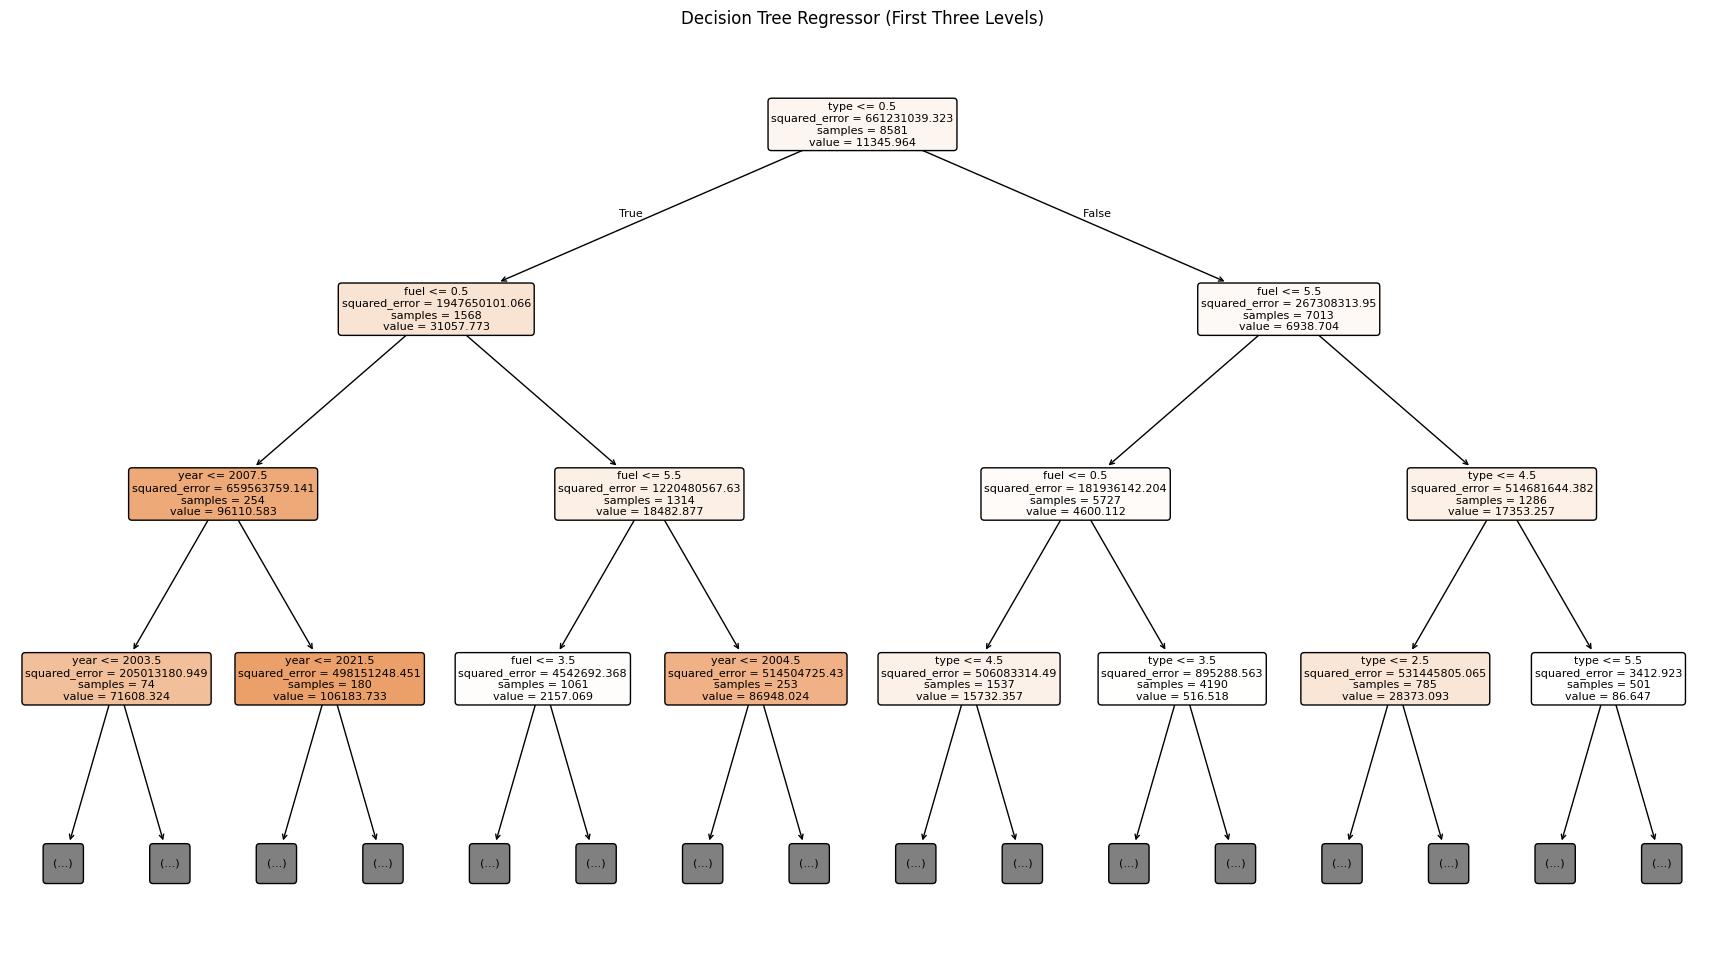

In [ ]:
plt.figure(figsize=(22,12))

plot_tree(
    optimized_model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree Regressor (First Three Levels)")

plt.show()

# Conclusion

• Successfully developed a Decision Tree Regressor model to predict vehicle registrations using vehicle type, fuel type, year, month, and day as input features.

• Evaluated the baseline model using MAE, MSE, RMSE, and R² Score to measure prediction accuracy.

• Applied GridSearchCV for hyperparameter optimization, resulting in an improved model with better predictive performance than the baseline.

• Identified the most influential features through feature importance analysis and visualized the model using a Decision Tree for better interpretability.

• Overall, the optimized Decision Tree Regressor demonstrated strong predictive capability and can support data-driven decision-making in vehicle registration forecasting.

**END OF DECISION TREE REGRESSOR**

**GRADIENT BOOSTING REGRESSOR**

1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

2. Load Dataset

In [ ]:
df = pd.read_csv('/content/cleaned_registrations.csv')
print("Dataset loaded successfully. Here are the first 5 rows:")
display(df.head())

Dataset loaded successfully. Here are the first 5 rows:


,type,fuel,registrations,year,month,day
0,0,0,51261,2000,1,1
1,0,0,46478,2000,2,1
2,0,0,57477,2000,3,1
3,0,0,50941,2000,4,1
4,0,0,53361,2000,5,1


3. Data Preprocessing & Feature Engineering

In [ ]:
print("\nDataset Information:")
display(df.info())

print("\nMissing values:")
display(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10727 entries, 0 to 10726
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   type           10727 non-null  int64
 1   fuel           10727 non-null  int64
 2   registrations  10727 non-null  int64
 3   year           10727 non-null  int64
 4   month          10727 non-null  int64
 5   day            10727 non-null  int64
dtypes: int64(6)
memory usage: 503.0 KB


None


Missing values:


,0
type,0
fuel,0
registrations,0
year,0
month,0
day,0


In [ ]:
# Identify potential target column for regression. Adjust 'target_column' if your dataset has a different name.
# Common names for registration counts could be 'Registrations', 'Number_of_Registrations', 'count', 'total'.
# For demonstration, I will assume a column named 'Total Registrations' exists. You might need to change this.

possible_target_columns = ['Number of Registrations', 'Registrations', 'registrations', 'registrations_count', 'total_registrations', 'count', 'total']
target_column = None

for col in possible_target_columns:
    if col in df.columns:
        target_column = col
        break

if target_column is None:
    print("Could not find a clear target column among common names. Please specify the target column for 'Number of Registrations' from the DataFrame's columns:")
    print(df.columns.tolist())
    # For now, let's assume the last numerical column as a placeholder if no clear target is found.
    # THIS IS A PLACEHOLDER - USER MIGHT NEED TO SPECIFY THE ACTUAL TARGET.
    numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
    if numerical_cols:
        target_column = numerical_cols[-1]
        print(f"Using '{target_column}' as a placeholder target column. **Please confirm if this is correct.**")
    else:
        raise ValueError("No numerical columns found to be used as a target variable. Please specify the target column.")


y = df[target_column]
X = df.drop(columns=[target_column])

# Handle categorical features using one-hot encoding
X = pd.get_dummies(X, drop_first=True)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nFeatures (X) and target (y) prepared. Using '{target_column}' as the target variable.")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")


Features (X) and target (y) prepared. Using 'registrations' as the target variable.
X_train shape: (8581, 5), y_train shape: (8581,)
X_test shape: (2146, 5), y_test shape: (2146,)


4. Train the Gradient Boosting Regressor Model

In [ ]:
gbr_model = GradientBoostingRegressor(random_state=42)
gbr_model.fit(X_train, y_train)

print("Gradient Boosting Regressor model trained successfully.")

Gradient Boosting Regressor model trained successfully.


5. Model Evaluation

In [ ]:
y_pred = gbr_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Absolute Error (MAE): 4119.2020
Mean Squared Error (MSE): 49607348.9916
Root Mean Squared Error (RMSE): 7043.2485
R-squared (R2): 0.9278


6. Performance Visualizations

6.1 Actual vs Predicted Values Plot

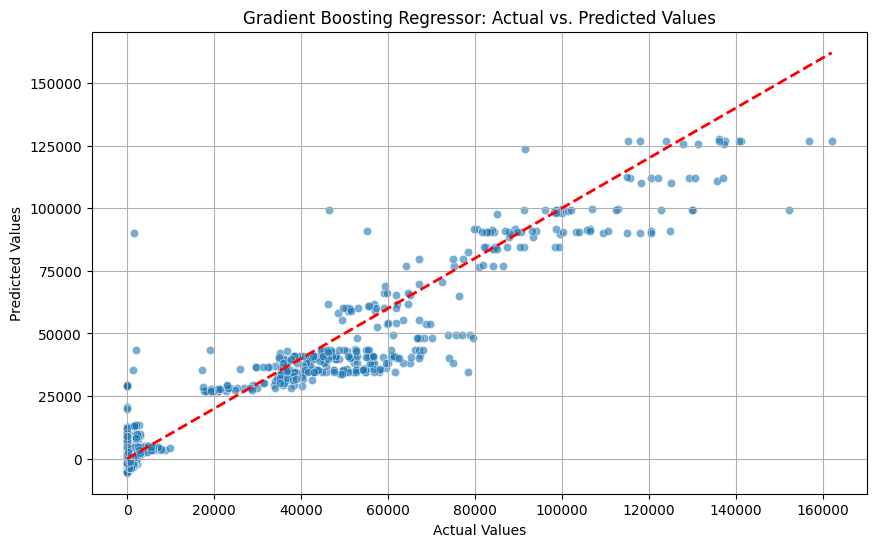

In [ ]:
# Plotting Actual vs. Predicted Values
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Gradient Boosting Regressor: Actual vs. Predicted Values")
plt.grid(True)
plt.show()

6.2 Residual Plot

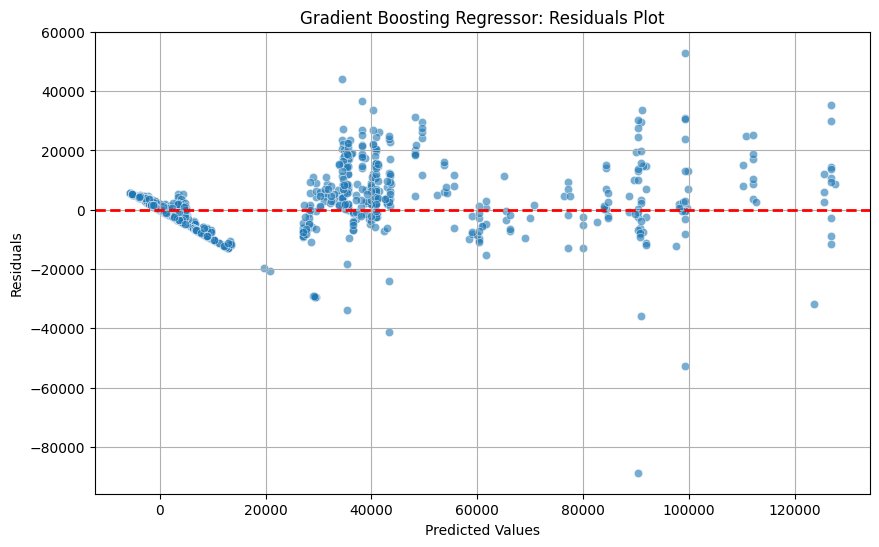

In [ ]:
# Plotting Residuals
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Gradient Boosting Regressor: Residuals Plot")
plt.grid(True)
plt.show()

**END OF GRADIENT BOOSTING REGRESSOR**

# Model Comparison

MAE and RMSE Error Comparison Between Regression Models

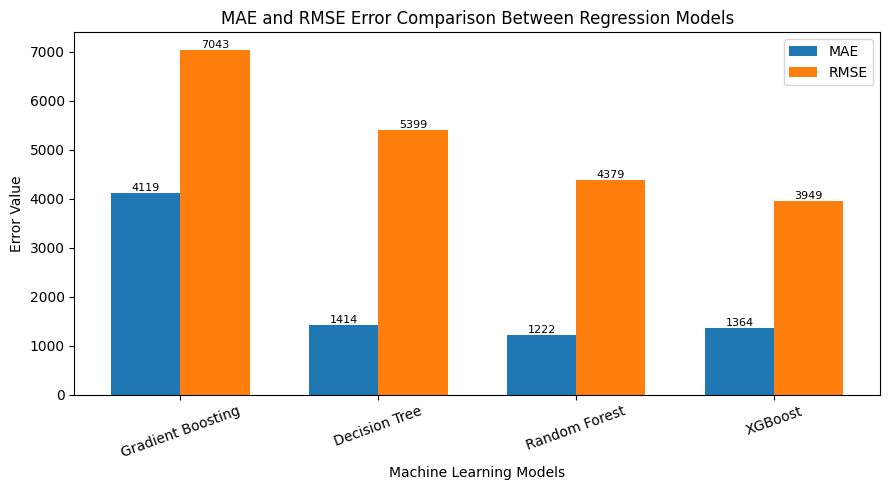

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = [
    "Gradient Boosting",
    "Decision Tree",
    "Random Forest",
    "XGBoost"
]

# Final model results
mae = [
    4119.2020,
    1413.7008,
    1221.7706,
    1364.47
]

rmse = [
    7043.2485,
    5399.1303,
    4378.9480,
    3948.75
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9,5))

plt.bar(x - width/2, mae, width, label="MAE")
plt.bar(x + width/2, rmse, width, label="RMSE")

plt.xlabel("Machine Learning Models")
plt.ylabel("Error Value")
plt.title("MAE and RMSE Error Comparison Between Regression Models")

plt.xticks(x, models, rotation=20)
plt.legend()

# Add values above bars
for i in range(len(models)):
    plt.text(
        x[i]-width/2,
        mae[i],
        f"{mae[i]:.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

    plt.text(
        x[i]+width/2,
        rmse[i],
        f"{rmse[i]:.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

R² Score Comparison Between Regression Models

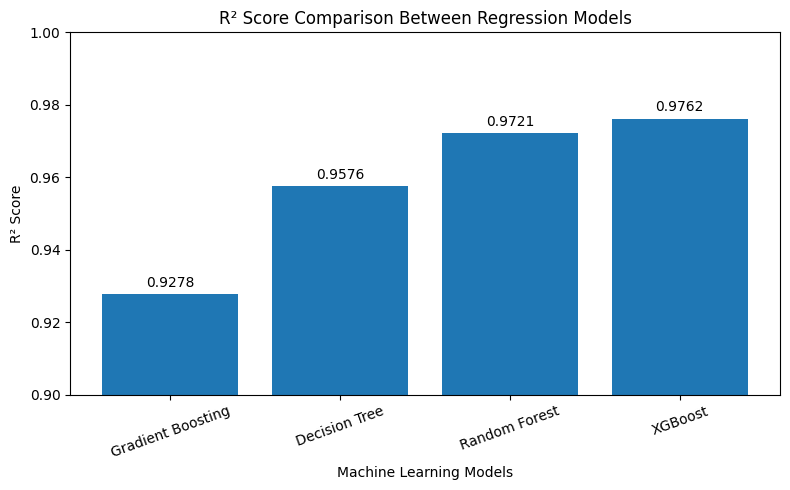

In [ ]:
import matplotlib.pyplot as plt

# Model names
models = [
    "Gradient Boosting",
    "Decision Tree",
    "Random Forest",
    "XGBoost"
]

# Final R² results
r2_scores = [
    0.9278,
    0.9576,
    0.9721,
    0.9762
]

plt.figure(figsize=(8,5))

plt.bar(models, r2_scores)

plt.xlabel("Machine Learning Models")
plt.ylabel("R² Score")
plt.title("R² Score Comparison Between Regression Models")

plt.ylim(0.90, 1.00)

# Display score values
for i, value in enumerate(r2_scores):
    plt.text(
        i,
        value + 0.002,
        f"{value:.4f}",
        ha="center"
    )

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()